# Exploration & results

Exploratory analysis of the [weather prediction dataset](https://doi.org/10.5281/zenodo.7525955) and a summary of the
model results produced by `maxtemp train`.

The modelling code lives in the `maxtemp` package (`src/maxtemp`); this notebook only explores the data and reads the
saved report, so it runs in a few seconds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from maxtemp.data import available_cities, clean_dataset, load_dataset, make_supervised
from maxtemp.plots import INK_SECONDARY, MODEL_COLORS, _style

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw = load_dataset(ROOT / "data" / "weather_prediction_dataset.csv")
print(
    f"{raw.shape[0]} days ({raw.index.min():%Y-%m-%d} - {raw.index.max():%Y-%m-%d}), "
    f"{raw.shape[1]} columns, {len(available_cities(raw))} locations"
)

3654 days (2000-01-01 - 2010-01-01), 164 columns, 18 locations


## 1. Data quality

The dataset has no `NaN`s, but a few missing observations are encoded with *sentinel* values that are physically
impossible (negative sunshine hours, cloud cover of −99 oktas, air pressure of 0). Left in place they look like extreme
measurements to a neural network; before cleaning, the network's test RMSE was 4–6 °C instead of ~2 °C.
`clean_dataset` replaces them with the last valid observation.

In [2]:
df, fixed = clean_dataset(raw)
pd.Series(fixed, name="invalid values replaced").to_frame()

,invalid values replaced
STOCKHOLM_cloud_cover,2
STOCKHOLM_pressure,3
STOCKHOLM_sunshine,29
TOURS_pressure,1


In [3]:
raw.loc[raw["STOCKHOLM_cloud_cover"] < 0, ["STOCKHOLM_cloud_cover"]].join(
    df["STOCKHOLM_cloud_cover"].rename("after cleaning")
)

,STOCKHOLM_cloud_cover,after cleaning
date,,
2008-07-24,-99,1.0
2009-06-25,-99,0.0


## 2. Seasonality of the three target cities

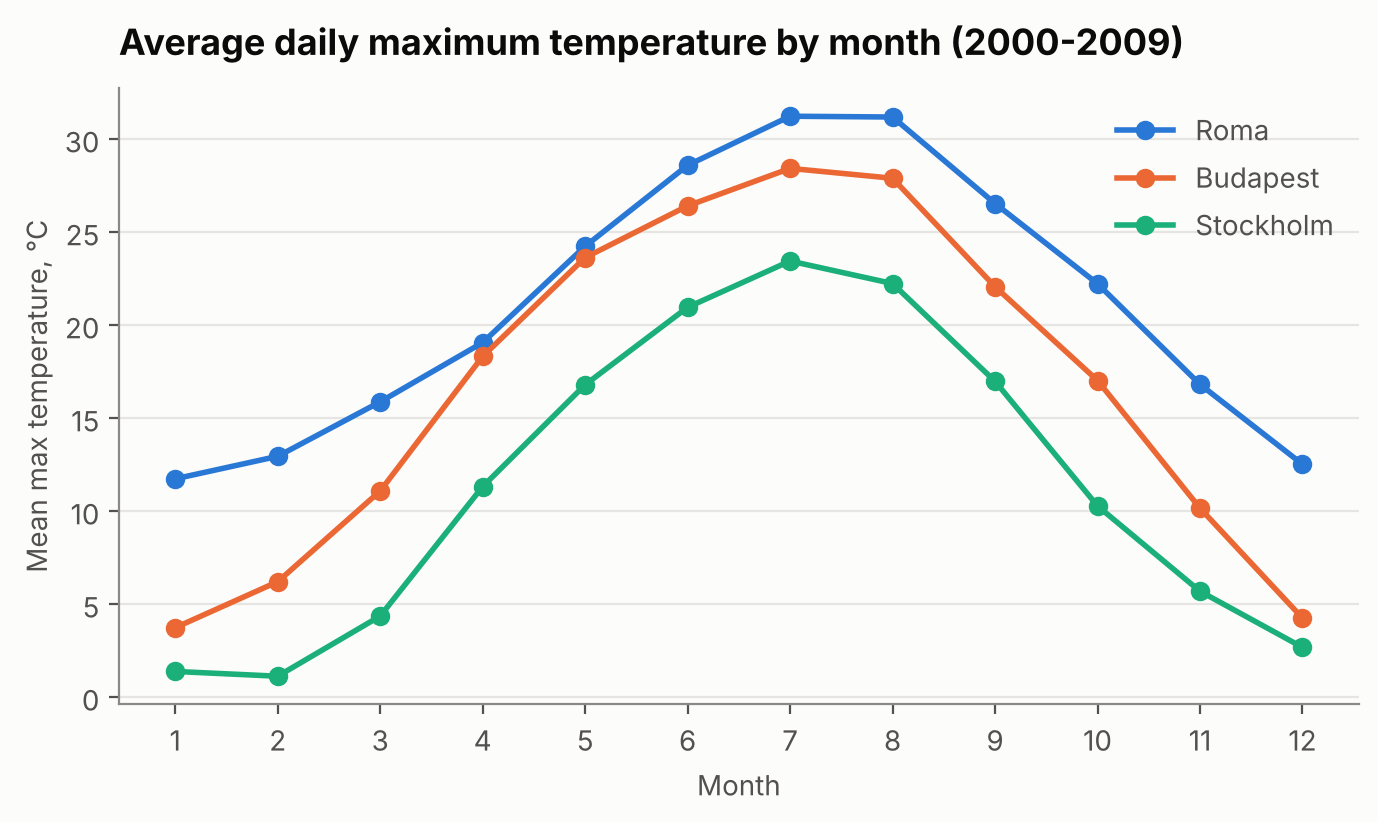

In [4]:
CITIES = ["ROMA", "BUDAPEST", "STOCKHOLM"]
monthly = df[[f"{c}_temp_max" for c in CITIES]].groupby(df.index.month).mean()

fig, ax = plt.subplots(figsize=(8, 4))
for city, color in zip(CITIES, MODEL_COLORS.values(), strict=True):
    ax.plot(
        monthly.index,
        monthly[f"{city}_temp_max"],
        color=color,
        linewidth=2,
        marker="o",
        label=city.title(),
    )
ax.set(
    xticks=range(1, 13),
    xlabel="Month",
    ylabel="Mean max temperature, °C",
    title="Average daily maximum temperature by month (2000-2009)",
)
ax.legend()
_style(ax)

## 3. What predicts tomorrow's maximum in Rome?

Correlation between today's observations (all 18 locations) and tomorrow's maximum temperature in Rome.

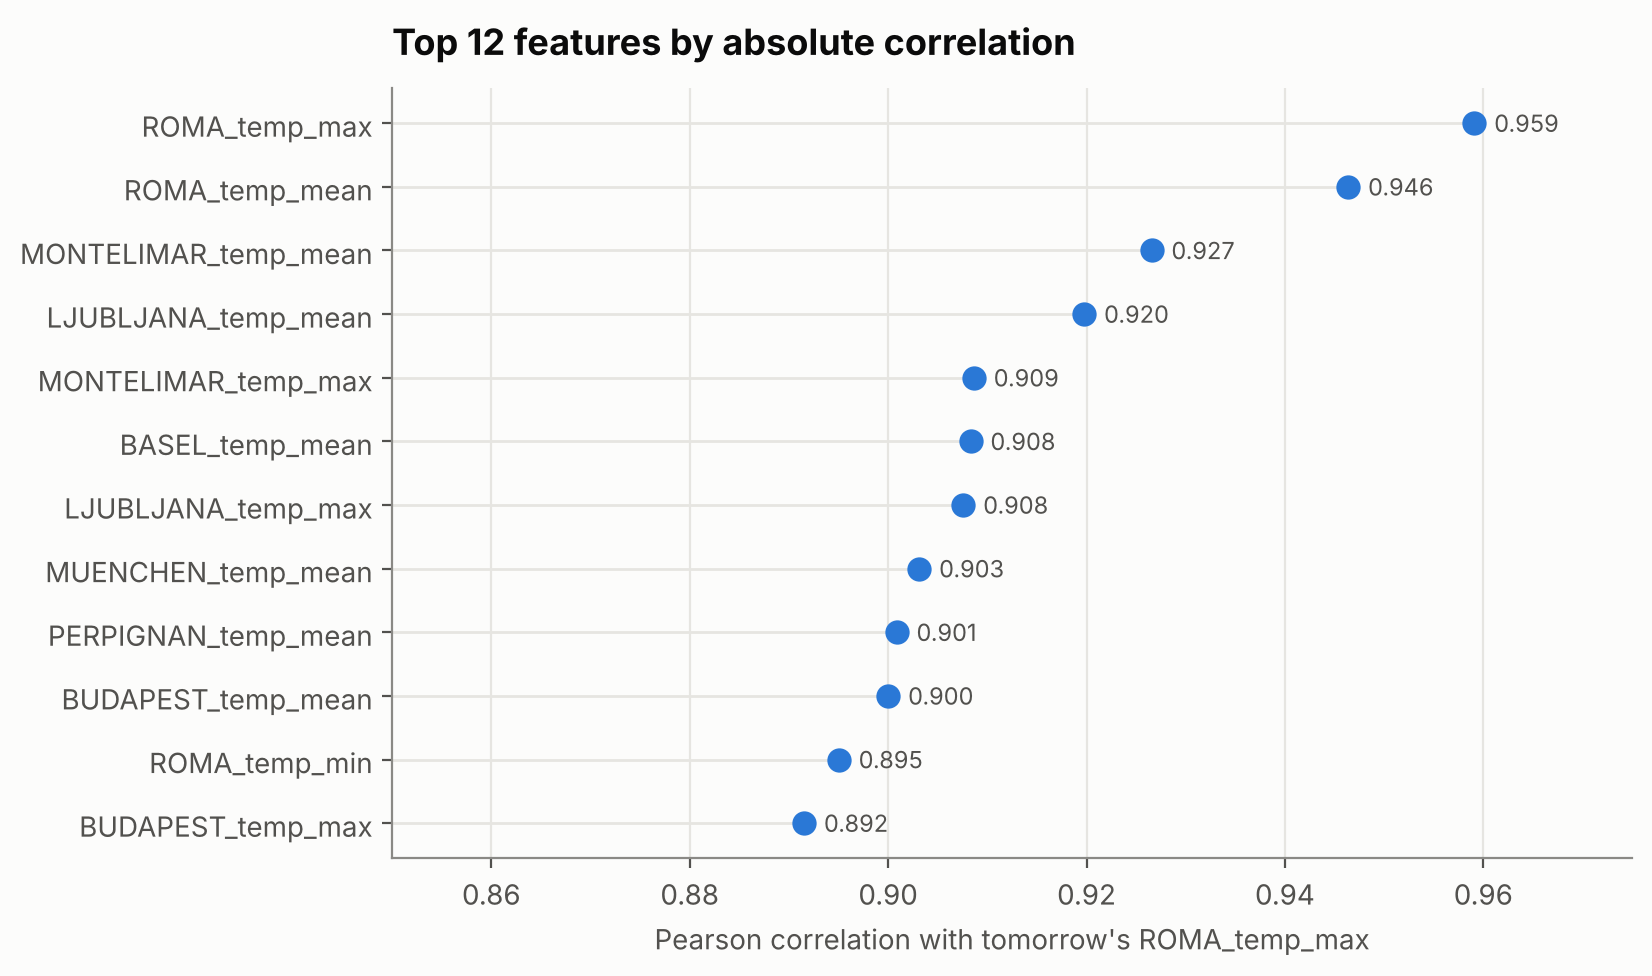

In [5]:
X, y = make_supervised(df, "ROMA")
corr = X.corrwith(y).dropna().sort_values(key=abs, ascending=False).head(12)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
# A dot plot instead of bars: the axis does not start at zero, so bar lengths would mislead.
ax.hlines(corr.index, 0.85, corr.values, color="#e6e5e1", linewidth=1)
ax.scatter(corr.values, corr.index, s=60, color=MODEL_COLORS["mlp"], zorder=3)
ax.set(
    xlabel="Pearson correlation with tomorrow's ROMA_temp_max",
    xlim=(0.85, 0.975),
    title="Top 12 features by absolute correlation",
)
for i, v in enumerate(corr.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK_SECONDARY)
_style(ax, grid_axis="x")

Today's temperatures in Rome and in the other southern locations are almost perfectly correlated with tomorrow's
maximum. That is why the naive *persistence* forecast ("tomorrow = today") is already a strong baseline, and why a
regularised linear model is hard to beat on this dataset.

## 4. Results

Metrics on the 2008–2009 test period, read from `reports/metrics.json` (re-create with `maxtemp train`).

In [6]:
report = json.loads((ROOT / "reports" / "metrics.json").read_text())
rows = [
    {
        "city": city.title(),
        "model": model,
        **{k: round(v, 3) for k, v in res[model].items() if k in ("rmse", "mae", "r2")},
    }
    for city, res in report["results"].items()
    for model in ("persistence", "ridge", "mlp")
]
pd.DataFrame(rows).pivot(index="city", columns="model", values="rmse")[
    ["persistence", "ridge", "mlp"]
]

model,persistence,ridge,mlp
city,,,
Budapest,2.804,2.141,2.288
Roma,2.195,1.931,2.040
Stockholm,2.318,1.964,2.175


In [7]:
pd.DataFrame(
    {
        city.title(): {
            "MC-dropout mean std, °C": round(res["mlp"]["mean_uncertainty_std"], 2),
            "Coverage of ±1.96 std band": f"{res['mlp']['interval_95_coverage']:.0%}",
        }
        for city, res in report["results"].items()
    }
).T

,"MC-dropout mean std, °C",Coverage of ±1.96 std band
Roma,0.89,65%
Budapest,0.96,59%
Stockholm,0.93,59%


**Takeaways**

* Both learned models beat persistence in every city.
* Ridge regression is slightly more accurate than the neural network. With ~2,500 training days and 165 strongly
  correlated, mostly linear features, the extra capacity of a network mainly adds variance.
* The network's advantage is a per-forecast uncertainty estimate (Monte Carlo dropout). The ±1.96 std band covers only
  ~60 % of observations, though: MC dropout captures *model* uncertainty, not the day-to-day noise of the weather, so the
  band is too narrow to be used as a real 95 % prediction interval.